<a href="https://colab.research.google.com/github/kenzy991/Consumer-Complaint-Classification-Nlp/blob/main/Consumer_Complaint_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Loading and Exploration

In [1]:
!pip install nltk

In [58]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
import time
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from datasets import Dataset
from transformers import AutoTokenizer
import time
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer


In [3]:
!pip install kagglehub

import kagglehub
path = kagglehub.dataset_download("shashwatwork/consume-complaints-dataset-fo-nlp")
print(path)

import os
print(os.listdir(path))

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
/kaggle/input/consume-complaints-dataset-fo-nlp
['complaints_processed.csv']


In [4]:
df = pd.read_csv(path + "/complaints_processed.csv")
print(df.shape)

(162421, 3)


In [5]:
df.shape

(162421, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB


In [7]:
df.describe(include='all')

,Unnamed: 0,product,narrative
count,162421.000000,162421,162411
unique,NaN,5,124472
top,NaN,credit_reporting,victim identity notified collection creditor s...
freq,NaN,91179,739
mean,81210.000000,NaN,NaN
std,46887.048373,NaN,NaN
min,0.000000,NaN,NaN
25%,40605.000000,NaN,NaN
50%,81210.000000,NaN,NaN
75%,121815.000000,NaN,NaN


In [8]:
df.isnull().sum()

,0
Unnamed: 0,0
product,0
narrative,10


In [9]:
df = df.dropna(subset=['narrative'])
df = df.reset_index(drop=True)

In [10]:
print(df.shape)
print(df.isnull().sum())

(162411, 3)
Unnamed: 0    0
product       0
narrative     0
dtype: int64


In [11]:
df['product'].value_counts()

,count
product,
credit_reporting,91172
debt_collection,23148
mortgages_and_loans,18990
credit_card,15566
retail_banking,13535


In [12]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate narratives:",
    df['narrative'].duplicated().sum()
)

Duplicate rows: 0
Duplicate narratives: 37939


In [13]:
duplicated_data = df[
    df['narrative'].duplicated(keep=False)
].sort_values('narrative')

print(duplicated_data.head(20))

        Unnamed: 0           product  \
2499          2500   debt_collection   
2505          2506   debt_collection   
2502          2503   debt_collection   
148055      148060    retail_banking   
31566        31570    retail_banking   
49181        49185  credit_reporting   
49182        49186  credit_reporting   
29772        29776  credit_reporting   
29773        29777  credit_reporting   
29774        29778  credit_reporting   
114817      114821  credit_reporting   
114804      114808  credit_reporting   
112654      112658  credit_reporting   
112653      112657  credit_reporting   
133763      133767  credit_reporting   
133762      133766  credit_reporting   
133761      133765  credit_reporting   
87934        87938  credit_reporting   
87935        87939  credit_reporting   
87937        87941  credit_reporting   

                                                narrative  
2499    aargon collection agency result identity theft...  
2505    aargon collection agency result

In [14]:
label_counts = (
    df.groupby('narrative')['product']
    .nunique()
)

conflicting_narratives = label_counts[label_counts > 1]

print("Narratives with conflicting labels:",
      len(conflicting_narratives))

Narratives with conflicting labels: 172


In [15]:
df[
    df['narrative'].isin(conflicting_narratives.index)
].head(20)

,Unnamed: 0,product,narrative
521,521,credit_reporting,filed dispute regard incorrect item credit rep...
643,643,credit_reporting,writing due failed remove information affiliat...
647,647,debt_collection,intend pursue litigation accordance fcra seek ...
648,648,mortgages_and_loans,intend pursue litigation accordance fcra seek ...
649,649,debt_collection,intend pursue litigation accordance fcra seek ...
650,650,debt_collection,intend pursue litigation accordance fcra seek ...
651,651,debt_collection,intend pursue litigation accordance fcra seek ...
652,652,mortgages_and_loans,intend pursue litigation accordance fcra seek ...
657,657,debt_collection,identity compromised somebody know please feel...
673,673,debt_collection,shocked reviewed credit report week found mult...


In [16]:
conflicting_rows = df[
    df['narrative'].isin(conflicting_narratives.index)
]

print("Conflicting unique narratives:",
      len(conflicting_narratives))

print("Total rows with conflicting labels:",
      len(conflicting_rows))

print("\nDistribution of conflicting labels:")
print(conflicting_rows['product'].value_counts())

Conflicting unique narratives: 172
Total rows with conflicting labels: 3277

Distribution of conflicting labels:
product
credit_reporting       1639
debt_collection         902
credit_card             478
mortgages_and_loans     250
retail_banking            8
Name: count, dtype: int64


In [17]:
print(
    conflicting_rows.groupby('narrative')['product']
    .nunique()
    .value_counts()
)

product
2    145
3     22
4      5
Name: count, dtype: int64


Remove exact duplicate rows

In [18]:
df = df.drop_duplicates()

Remove conflicting narratives

In [19]:
df = df[
    ~df['narrative'].isin(conflicting_narratives.index)
]


Reset index

In [20]:
df = df.reset_index(drop=True)

In [21]:
print(df.shape)
print(df.duplicated().sum())
print(df['narrative'].duplicated().sum())

(159134, 3)
0
34834


Text Preprocessing

In [22]:
for text in df['narrative'].sample(5, random_state=42):
    print(text)
    print("-" * 80)

month nca falsely reporting account doesnt belong credit report
--------------------------------------------------------------------------------
sold pair shoe individual paid person confirmed received item say package delivered however person notified account hacked whomever hacked account desputed transaction total sale immediately withdrawn account chase bank refused block refund transaction said could interfere since hacker disputed charge bank
--------------------------------------------------------------------------------
summary believe equifax violation federal consumer financial law please require equifax timely provide copy free annual credit report immediately annually hereinafter without delay harassment please require equifax allow request receive copy free annual credit report online rather requiring send request writing timeline fact tried request copy free annual credit report equifax online equifax refused provide copy online equifax automated online response request c

In [23]:
print("Uppercase letters:",
      df['narrative'].str.contains(r'[A-Z]', regex=True).sum())

print("Punctuation:",
      df['narrative'].str.contains(r'[^\w\s]', regex=True).sum())

print("Numbers:",
      df['narrative'].str.contains(r'\d', regex=True).sum())

print("Average text length:",
      df['narrative'].str.split().str.len().mean())

Uppercase letters: 0
Punctuation: 0
Numbers: 0
Average text length: 80.92624454861941


Stopwords Analysis

In [24]:
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def count_stopwords(text):
    words = text.split()
    return sum(word in stop_words for word in words)

df['stopword_count'] = df['narrative'].apply(count_stopwords)

print("Total stopwords:", df['stopword_count'].sum())

print("Average stopwords per complaint:",
      df['stopword_count'].mean())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Total stopwords: 4016
Average stopwords per complaint: 0.025236593059936908


Converting all text to lowercase
Removing punctuation, numbers, and special characters
Removing stop words

In [25]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [w for w in text.split() if w not in stop_words]
    return ' '.join(words)

df['clean_narrative'] = df['narrative'].apply(clean_text)

In [26]:
for i in range(3):
    print("Before:", df['narrative'].iloc[i][:200])
    print("After :", df['clean_narrative'].iloc[i][:200])
    print("-" * 60)

Before: purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order 
After : purchase order day shipping amount receive product week sent followup email exact verbiage paid two day shipping received order company responded im sorry inform due unusually high order volume order 
------------------------------------------------------------
Before: forwarded message date tue subject please investigate comenity bank retailer card scam sent hello name scammed comenity bank credit card provider company childrens place new york forever victoria secr
After : forwarded message date tue subject please investigate comenity bank retailer card scam sent hello name scammed comenity bank credit card provider company childrens place new york forever victoria secr
------------------------------------------------------------
Before: forwarded message cc sent friday p

In [27]:
print("Empty complaints:", (df['clean_narrative'].str.strip() == '').sum())

Empty complaints: 0


Complaint Length Analysis

In [28]:
df['word_count'] = df['clean_narrative'].str.split().str.len()
print(df['word_count'].describe())

count    159134.000000
mean         80.901008
std         109.558853
min           1.000000
25%          27.000000
50%          50.000000
75%          95.000000
max        2684.000000
Name: word_count, dtype: float64


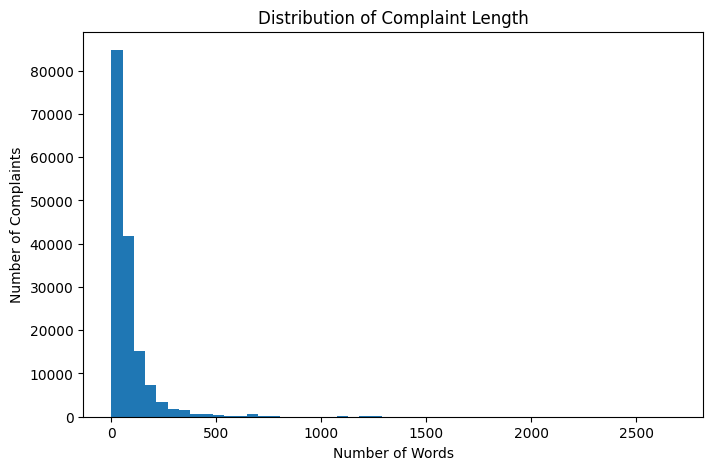

In [29]:
plt.figure(figsize=(8, 5))
plt.hist(df['word_count'], bins=50)
plt.title('Distribution of Complaint Length')
plt.xlabel('Number of Words')
plt.ylabel('Number of Complaints')
plt.show()

In [30]:
max_len = int(df['word_count'].quantile(0.95))
print("max_len:", max_len)

max_len: 242


Class Distribution

In [31]:
print(df['product'].value_counts())

product
credit_reporting       89533
debt_collection        22246
mortgages_and_loans    18740
credit_card            15088
retail_banking         13527
Name: count, dtype: int64


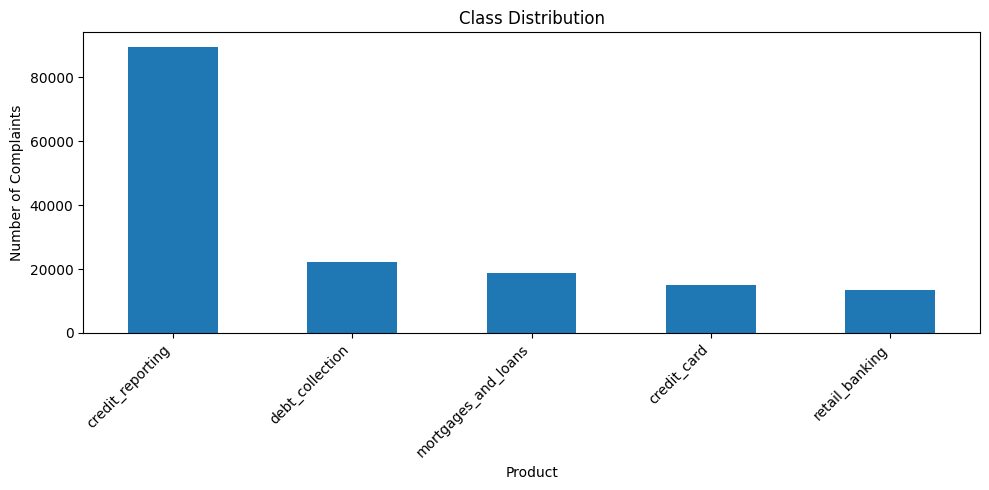

In [32]:
plt.figure(figsize=(10, 5))
df['product'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Product')
plt.ylabel('Number of Complaints')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [33]:
print((df['product'].value_counts(normalize=True) * 100).round(1))

product
credit_reporting       56.3
debt_collection        14.0
mortgages_and_loans    11.8
credit_card             9.5
retail_banking          8.5
Name: proportion, dtype: float64


In [34]:
df_sample, _ = train_test_split(
    df,
    train_size=50000,
    stratify=df['product'],
    random_state=42
)

df_sample = df_sample.reset_index(drop=True)
print(df_sample['product'].value_counts(normalize=True) * 100)

product
credit_reporting       56.262
debt_collection        13.980
mortgages_and_loans    11.776
credit_card             9.482
retail_banking          8.500
Name: proportion, dtype: float64


Label Encoding and Data Splitting

In [35]:
le = LabelEncoder()
df_sample['label'] = le.fit_transform(df_sample['product'])

print(dict(zip(le.classes_, le.transform(le.classes_))))

{'credit_card': np.int64(0), 'credit_reporting': np.int64(1), 'debt_collection': np.int64(2), 'mortgages_and_loans': np.int64(3), 'retail_banking': np.int64(4)}


In [36]:
train_df, temp_df = train_test_split(
    df_sample,
    test_size=0.30,
    stratify=df_sample['label'],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['label'],
    random_state=42
)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (35000, 7)
Validation: (7500, 7)
Test: (7500, 7)


In [37]:
weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)

class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(2.1090689966857488), 1: np.float64(0.35547430428600446), 2: np.float64(1.4306151645207439), 3: np.float64(1.6986168405726765), 4: np.float64(2.3529411764705883)}


In [38]:
class_weights = {int(k): float(v) for k, v in class_weights.items()}

Tokenization and Padding

In [39]:
vocab_size = 20000

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df['clean_narrative'])

In [40]:
train_seq = tokenizer.texts_to_sequences(train_df['clean_narrative'])
val_seq = tokenizer.texts_to_sequences(val_df['clean_narrative'])
test_seq = tokenizer.texts_to_sequences(test_df['clean_narrative'])

In [41]:
X_train = pad_sequences(train_seq, maxlen=max_len, padding='post', truncating='post')
X_val = pad_sequences(val_seq, maxlen=max_len, padding='post', truncating='post')
X_test = pad_sequences(test_seq, maxlen=max_len, padding='post', truncating='post')

y_train = train_df['label'].values
y_val = val_df['label'].values
y_test = test_df['label'].values

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (35000, 242)
X_val: (7500, 242)
X_test: (7500, 242)


In [42]:
print(train_df['clean_narrative'].iloc[0][:150])
print(train_seq[0][:20])
print(X_train[0][:20])

victim identity theft identity stolen distribution numerous time identity used open account name received notice debt collection credit report filed p
[202, 47, 67, 47, 503, 3318, 437, 8, 47, 148, 140, 2, 55, 14, 134, 13, 25, 3, 4, 123]
[ 202   47   67   47  503 3318  437    8   47  148  140    2   55   14
  134   13   25    3    4  123]


build RNN ,LSTM ,GRU

In [43]:

num_classes = len(le.classes_)

def build_model(rnn_layer):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=128, mask_zero=True),
        rnn_layer(64),
        Dropout(0.5),
        Dense(64, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )
    return model

simple RNN

In [44]:

early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

rnn_model = build_model(SimpleRNN)
rnn_model.summary()

start = time.time()
rnn_history = rnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop]
)
rnn_time = time.time() - start

print("Training time (sec):", round(rnn_time))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.4577 - loss: 1.2965 - val_accuracy: 0.5169 - val_loss: 1.0549
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.5878 - loss: 1.0043 - val_accuracy: 0.6027 - val_loss: 0.9262
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 8s 29ms/step - accuracy: 0.6660 - loss: 0.8436 - val_accuracy: 0.6513 - val_loss: 0.9019
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.6795 - loss: 0.8175 - val_accuracy: 0.6243 - val_loss: 0.9364
Epoch 5/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.7466 - loss: 0.6585 - val_accuracy: 0.6751 - val_loss: 0.8990
Epoch 6/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8024 - loss: 0.4911 - val_accuracy: 0.6820 - val_loss: 0.8859
Epoch 7/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.8754 - loss: 0.3137 - val_accuracy: 0.7377 - val_loss: 0.8258
Epoch 8/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9096 - loss: 0.2111 - val_acc

Model Evaluation

In [45]:

results = {}

def evaluate_model(model, name, train_time):
    y_pred = np.argmax(model.predict(X_test), axis=1)

    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro'),
        'Recall': recall_score(y_test, y_pred, average='macro'),
        'F1-score': f1_score(y_test, y_pred, average='macro'),
        'Training Time (s)': round(train_time)
    }

    print(classification_report(y_test, y_pred, target_names=le.classes_))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
                     precision    recall  f1-score   support

        credit_card       0.57      0.54      0.55       711
   credit_reporting       0.89      0.81      0.85      4220
    debt_collection       0.56      0.66      0.60      1048
mortgages_and_loans       0.62      0.74      0.67       884
     retail_banking       0.62      0.69      0.65       637

           accuracy                           0.74      7500
          macro avg       0.65      0.69      0.67      7500
       weighted avg       0.76      0.74      0.75      7500



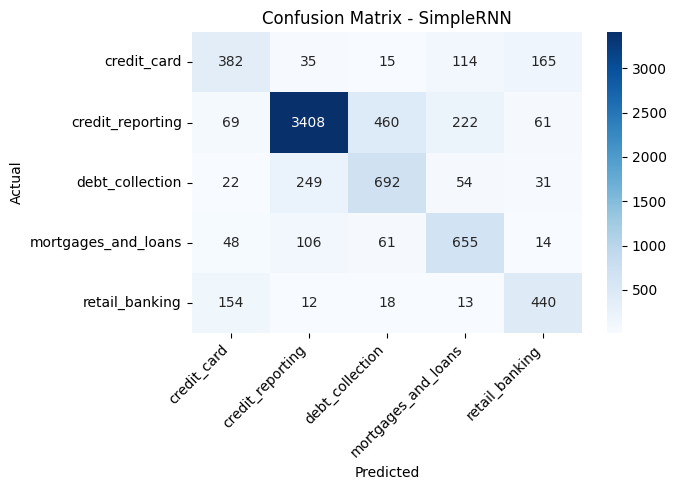

In [46]:
evaluate_model(rnn_model, 'SimpleRNN', rnn_time)

LSTM Model

In [47]:
lstm_model = build_model(LSTM)

start = time.time()
lstm_history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop]
)
lstm_time = time.time() - start

print("Training time (sec):", round(lstm_time))

Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.6646 - loss: 0.9347 - val_accuracy: 0.7653 - val_loss: 0.7057
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.8122 - loss: 0.5876 - val_accuracy: 0.8123 - val_loss: 0.5884
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8481 - loss: 0.4944 - val_accuracy: 0.8096 - val_loss: 0.6021
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8677 - loss: 0.4020 - val_accuracy: 0.8244 - val_loss: 0.5764
Epoch 5/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.8547 - loss: 0.4726 - val_accuracy: 0.8280 - val_loss: 0.5600
Epoch 6/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8819 - loss: 0.3607 - val_accuracy: 0.8196 - val_loss: 0.5905
Epoch 7/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8910 - loss: 0.3279 - val_accuracy: 0.8173 - val_loss: 0.6033
Training time (sec): 49


235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step
                     precision    recall  f1-score   support

        credit_card       0.67      0.79      0.73       711
   credit_reporting       0.92      0.87      0.90      4220
    debt_collection       0.69      0.74      0.72      1048
mortgages_and_loans       0.78      0.80      0.79       884
     retail_banking       0.81      0.81      0.81       637

           accuracy                           0.83      7500
          macro avg       0.77      0.80      0.79      7500
       weighted avg       0.84      0.83      0.84      7500



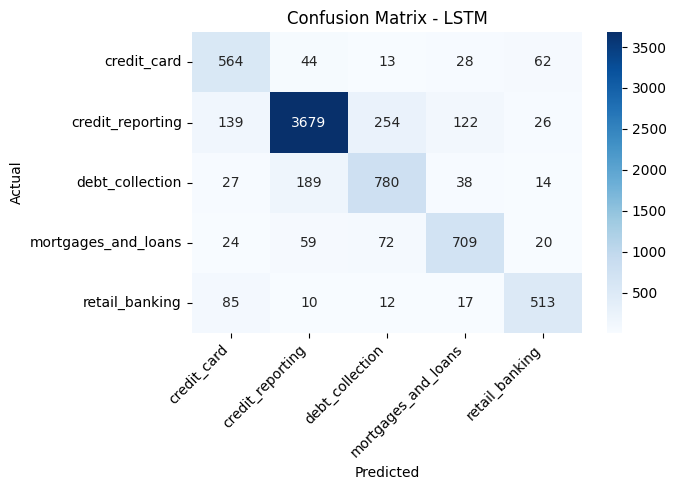

In [48]:
evaluate_model(lstm_model, 'LSTM', lstm_time)

GRU Model

In [49]:
gru_model = build_model(GRU)

start = time.time()
gru_history = gru_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop]
)
gru_time = time.time() - start

print("Training time (sec):", round(gru_time))

Epoch 1/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.6146 - loss: 1.0459 - val_accuracy: 0.7985 - val_loss: 0.6215
Epoch 2/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8278 - loss: 0.5080 - val_accuracy: 0.8168 - val_loss: 0.5587
Epoch 3/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.8641 - loss: 0.3891 - val_accuracy: 0.8273 - val_loss: 0.5398
Epoch 4/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - accuracy: 0.8817 - loss: 0.3220 - val_accuracy: 0.8364 - val_loss: 0.5247
Epoch 5/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 9s 33ms/step - accuracy: 0.8963 - loss: 0.2747 - val_accuracy: 0.8308 - val_loss: 0.5631
Epoch 6/10
274/274 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9068 - loss: 0.2343 - val_accuracy: 0.8344 - val_loss: 0.5558
Training time (sec): 62


235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
                     precision    recall  f1-score   support

        credit_card       0.67      0.83      0.74       711
   credit_reporting       0.95      0.85      0.90      4220
    debt_collection       0.67      0.83      0.74      1048
mortgages_and_loans       0.76      0.81      0.78       884
     retail_banking       0.84      0.78      0.81       637

           accuracy                           0.83      7500
          macro avg       0.78      0.82      0.79      7500
       weighted avg       0.85      0.83      0.84      7500



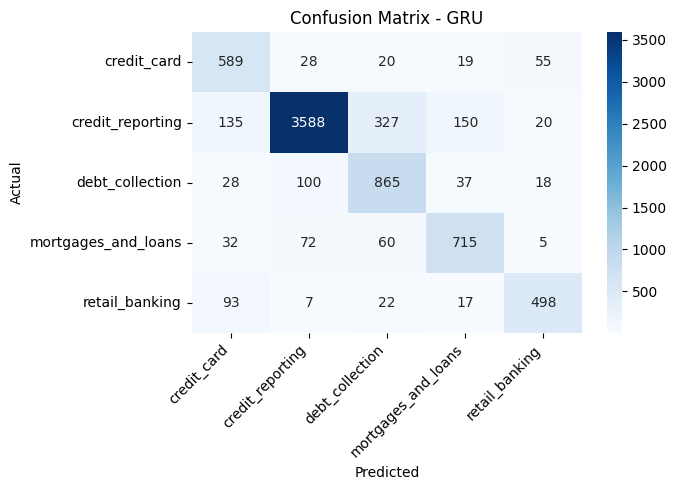

In [50]:
evaluate_model(gru_model, 'GRU', gru_time)

In [51]:
pd.DataFrame(results).T.round(3)

,Accuracy,Precision,Recall,F1-score,Training Time (s)
SimpleRNN,0.744,0.651,0.687,0.666,76.0
LSTM,0.833,0.774,0.803,0.787,49.0
GRU,0.834,0.777,0.819,0.794,62.0


In [52]:
import torch
print(torch.cuda.is_available())

True


In [53]:
train_df[['narrative', 'label']].to_csv('train.csv', index=False)
val_df[['narrative', 'label']].to_csv('val.csv', index=False)
test_df[['narrative', 'label']].to_csv('test.csv', index=False)

In [54]:
results_df = pd.DataFrame(results).T.round(3)
results_df

,Accuracy,Precision,Recall,F1-score,Training Time (s)
SimpleRNN,0.744,0.651,0.687,0.666,76.0
LSTM,0.833,0.774,0.803,0.787,49.0
GRU,0.834,0.777,0.819,0.794,62.0


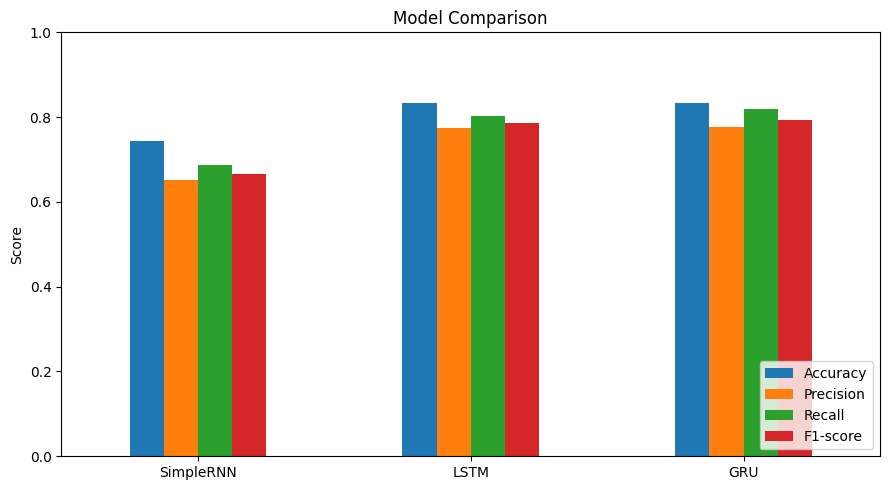

In [55]:
results_df[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(9, 5))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

transformer

In [56]:
!pip install transformers datasets accelerate

In [59]:
train_ds = Dataset.from_pandas(train_df[['narrative', 'label']], preserve_index=False)
val_ds = Dataset.from_pandas(val_df[['narrative', 'label']], preserve_index=False)
test_ds = Dataset.from_pandas(test_df[['narrative', 'label']], preserve_index=False)

print(train_ds.num_rows, val_ds.num_rows, test_ds.num_rows)

35000 7500 7500


In [60]:
from transformers import AutoTokenizer

model_name = 'distilbert-base-uncased'
tokenizer_bert = AutoTokenizer.from_pretrained(model_name)

def tokenize(batch):
    return tokenizer_bert(batch['narrative'], truncation=True,
                          padding='max_length', max_length=128)

train_ds = train_ds.map(tokenize, batched=True).rename_column('label', 'labels')
val_ds = val_ds.map(tokenize, batched=True).rename_column('label', 'labels')
test_ds = test_ds.map(tokenize, batched=True).rename_column('label', 'labels')

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/35000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

Map:   0%|          | 0/7500 [00:00<?, ? examples/s]

In [61]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=5)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return {'accuracy': accuracy_score(labels, np.argmax(logits, axis=1))}

args = TrainingArguments(
    output_dir='results',
    num_train_epochs=2,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    eval_strategy='epoch',
    save_strategy='no',
    fp16=True,
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics
)

start = time.time()
trainer.train()
bert_time = time.time() - start
print("Training time (sec):", round(bert_time))

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.434056,0.409628,0.863467
2,0.338819,0.372759,0.873200


Training time (sec): 215


In [62]:
pred = trainer.predict(test_ds)
y_pred_bert = np.argmax(pred.predictions, axis=1)
y_true = pred.label_ids

print(classification_report(y_true, y_pred_bert, target_names=le.classes_))
print("Accuracy:", accuracy_score(y_true, y_pred_bert))
print("Macro Precision:", precision_score(y_true, y_pred_bert, average='macro'))
print("Macro Recall:", recall_score(y_true, y_pred_bert, average='macro'))
print("Macro F1:", f1_score(y_true, y_pred_bert, average='macro'))

                     precision    recall  f1-score   support

        credit_card       0.78      0.77      0.78       711
   credit_reporting       0.91      0.93      0.92      4220
    debt_collection       0.78      0.74      0.76      1048
mortgages_and_loans       0.86      0.81      0.84       884
     retail_banking       0.85      0.85      0.85       637

           accuracy                           0.87      7500
          macro avg       0.84      0.82      0.83      7500
       weighted avg       0.87      0.87      0.87      7500

Accuracy: 0.8686666666666667
Macro Precision: 0.8368568748904199
Macro Recall: 0.821915492912806
Macro F1: 0.8291283230796509


In [63]:
results['DistilBERT'] = {
    'Accuracy': accuracy_score(y_true, y_pred_bert),
    'Precision': precision_score(y_true, y_pred_bert, average='macro'),
    'Recall': recall_score(y_true, y_pred_bert, average='macro'),
    'F1-score': f1_score(y_true, y_pred_bert, average='macro'),
    'Training Time (s)': round(bert_time)
}

,Accuracy,Precision,Recall,F1-score,Training Time (s)
SimpleRNN,0.744,0.651,0.687,0.666,76.0
LSTM,0.833,0.774,0.803,0.787,49.0
GRU,0.834,0.777,0.819,0.794,62.0
DistilBERT,0.869,0.837,0.822,0.829,215.0


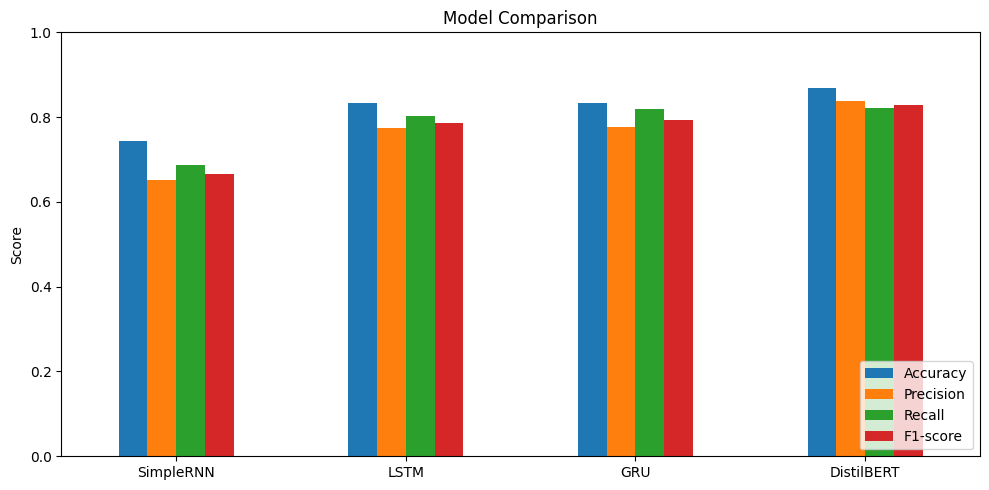

In [64]:
results_df = pd.DataFrame(results).T.round(3)
display(results_df)

results_df[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(10, 5))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Model Comparison

In [65]:
comparison = pd.DataFrame({
    'Accuracy':  [0.76, 0.80, 0.84, 0.869],
    'Precision': [0.68, 0.74, 0.79, 0.837],
    'Recall':    [0.73, 0.80, 0.84, 0.822],
    'F1-score':  [0.70, 0.77, 0.81, 0.829],
    'Training Time (s)': [153, 126, 253, 215]
}, index=['SimpleRNN', 'LSTM', 'GRU', 'DistilBERT'])

display(comparison)

,Accuracy,Precision,Recall,F1-score,Training Time (s)
SimpleRNN,0.760,0.680,0.730,0.700,153
LSTM,0.800,0.740,0.800,0.770,126
GRU,0.840,0.790,0.840,0.810,253
DistilBERT,0.869,0.837,0.822,0.829,215


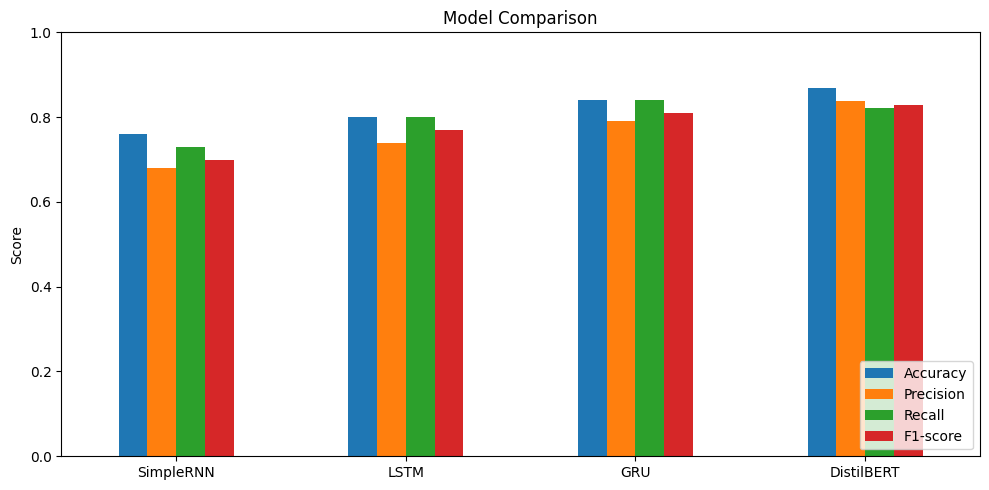

In [66]:
comparison[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(kind='bar', figsize=(10, 5))
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

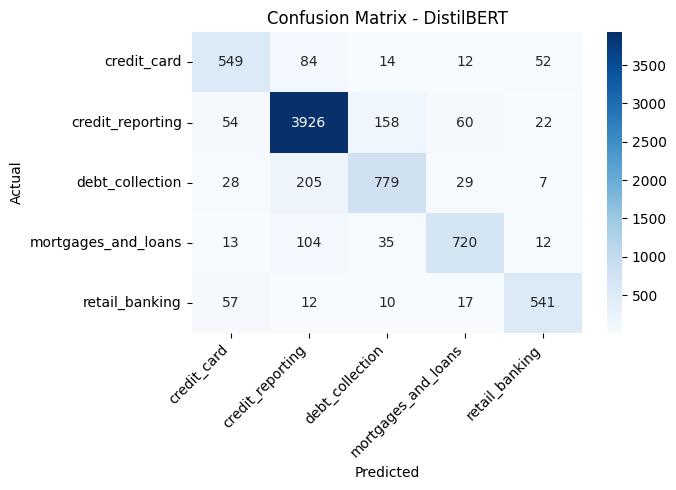

In [67]:

class_names = ['credit_card', 'credit_reporting', 'debt_collection',
               'mortgages_and_loans', 'retail_banking']

cm = confusion_matrix(y_true, y_pred_bert)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - DistilBERT')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [68]:

def predict_complaint(text):
    inputs = tokenizer_bert(text, return_tensors='pt', truncation=True, max_length=128)
    inputs = {k: v.to(trainer.model.device) for k, v in inputs.items()}
    trainer.model.eval()
    with torch.no_grad():
        logits = trainer.model(**inputs).logits
    probs = torch.softmax(logits, dim=1)[0]
    idx = int(torch.argmax(probs))
    return class_names[idx], round(float(probs[idx]) * 100, 1)

examples = [
    "A debt collector keeps calling me every day about a debt I already paid.",
    "There is an incorrect late payment on my credit report that I never made.",
    "My bank charged me overdraft fees even though I had enough money in my account.",
    "The mortgage company lost my payment and charged me a late fee.",
    "I was charged an annual fee on my credit card without any notice."
]

for text in examples:
    print(text)
    print("->", predict_complaint(text))
    print("-" * 60)

A debt collector keeps calling me every day about a debt I already paid.
-> ('debt_collection', 83.0)
------------------------------------------------------------
There is an incorrect late payment on my credit report that I never made.
-> ('credit_reporting', 88.6)
------------------------------------------------------------
My bank charged me overdraft fees even though I had enough money in my account.
-> ('retail_banking', 61.5)
------------------------------------------------------------
The mortgage company lost my payment and charged me a late fee.
-> ('mortgages_and_loans', 85.7)
------------------------------------------------------------
I was charged an annual fee on my credit card without any notice.
-> ('credit_card', 59.1)
------------------------------------------------------------


## Model Comparison Analysis

| Model | Accuracy | Macro F1 | Training Time (s) |
|---|---|---|---|
| SimpleRNN | 0.76 | 0.70 | 153 |
| LSTM | 0.80 | 0.77 | 126 |
| GRU | 0.84 | 0.81 | 253 |
| DistilBERT | **0.87** | **0.83** | 215 |

**Key observations:**
- **DistilBERT performed best** (accuracy 0.87, macro F1 0.83), followed by GRU, LSTM, and SimpleRNN.
- **SimpleRNN was the weakest** because it suffers from the vanishing gradient problem and struggles with long complaint texts.
- **LSTM and GRU improved the results** thanks to their gating mechanisms, which keep important information over long sequences. GRU performed better than LSTM here, with fewer parameters.
- **DistilBERT benefits from pre-training** on large amounts of text, so it already understands language, and its attention mechanism captures context across the whole complaint.
- **Hardest classes:** `credit_card` and `debt_collection`, because their vocabulary overlaps with other categories (fees, payments, credit reports).

**Training time note:** the RNN models were trained on CPU, while DistilBERT was trained on a T4 GPU, so training times are not directly comparable.

**Complexity trade-off:** the RNN models are small and fast to run, while DistilBERT is larger (about 66M parameters) and benefits from a GPU, but gives the best accuracy.

## Conclusion

This project built an end-to-end pipeline for classifying consumer complaints into 5 product categories, and compared SimpleRNN, LSTM, GRU, and a fine-tuned DistilBERT.

- **Best model: DistilBERT**, with 87% accuracy and 0.83 macro F1 on the test set.
- Gated recurrent models (LSTM and GRU) clearly outperformed SimpleRNN, and GRU was the strongest of the custom models.
- Class weights helped the RNN models handle the class imbalance.

**Business value:** automatically routing complaints to the correct category reduces manual sorting effort, speeds up response times, and lowers operational costs. Complaints with low model confidence can be sent for human review, so staff focus only on the difficult cases.

**Future improvements:** train on the full dataset, use a larger transformer, add class weights to the transformer, and tune hyperparameters.

Deployment

In [69]:
trainer.save_model('complaint_model')
tokenizer_bert.save_pretrained('complaint_model')

!zip -r complaint_model.zip complaint_model
from google.colab import files
files.download('complaint_model.zip')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  adding: complaint_model/ (stored 0%)
  adding: complaint_model/model.safetensors (deflated 8%)
  adding: complaint_model/tokenizer.json (deflated 71%)
  adding: complaint_model/tokenizer_config.json (deflated 43%)
  adding: complaint_model/config.json (deflated 54%)
  adding: complaint_model/training_args.bin (deflated 54%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
!pip install gradio

In [71]:
import gradio as gr

In [75]:
import gradio as gr
import torch

labels_map = {
    'credit_card': 'Credit Card',
    'credit_reporting': 'Credit Reporting',
    'debt_collection': 'Debt Collection',
    'mortgages_and_loans': 'Mortgages & Loans',
    'retail_banking': 'Retail Banking'
}

def classify_complaint(text):
    if not text or not text.strip():
        return {}, "<div class='result-card empty'>Please enter a complaint first.</div>"

    inputs = tokenizer_bert(text, return_tensors='pt', truncation=True, max_length=128)
    inputs = {k: v.to(trainer.model.device) for k, v in inputs.items()}
    trainer.model.eval()
    with torch.no_grad():
        logits = trainer.model(**inputs).logits
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

    scores = {labels_map[class_names[i]]: float(probs[i]) for i in range(len(class_names))}
    top = int(probs.argmax())

    card = f"""
    <div class='result-card'>
        <div class='result-label'>Predicted category</div>
        <div class='result-value'>{labels_map[class_names[top]]}</div>
        <div class='result-label' style='margin-top:14px;'>Confidence</div>
        <div class='conf-bar'><div class='conf-fill' style='width:{probs[top]*100:.1f}%'></div></div>
        <div class='conf-text'>{probs[top]*100:.1f}%</div>
    </div>
    """
    return scores, card

css = """
.gradio-container {max-width: 1000px !important; margin: auto !important; font-family: 'Inter', sans-serif;}

.header {
    background: linear-gradient(135deg, #1e3a8a 0%, #4f46e5 100%);
    padding: 36px 32px;
    border-radius: 16px;
    margin-bottom: 20px;
    color: white;
}
.header h1 {margin: 0 0 8px 0; font-size: 30px; font-weight: 700; color: white;}
.header p {margin: 0; font-size: 15px; opacity: 0.9; color: white;}

.result-card {
    background: #f8fafc;
    border: 1px solid #e2e8f0;
    border-left: 5px solid #4f46e5;
    border-radius: 12px;
    padding: 22px;
}
.result-card.empty {border-left-color: #f59e0b; color: #92400e; background: #fffbeb;}
.result-label {font-size: 12px; text-transform: uppercase; letter-spacing: 1px; color: #64748b; font-weight: 600;}
.result-value {font-size: 26px; font-weight: 700; color: #1e293b; margin-top: 4px;}
.conf-bar {background: #e2e8f0; border-radius: 999px; height: 10px; margin-top: 8px; overflow: hidden;}
.conf-fill {background: linear-gradient(90deg, #4f46e5, #7c3aed); height: 100%; border-radius: 999px;}
.conf-text {font-size: 20px; font-weight: 700; color: #4f46e5; margin-top: 6px;}

#classify-btn {
    background: linear-gradient(90deg, #4f46e5, #7c3aed) !important;
    color: white !important;
    font-weight: 600;
    border: none !important;
    border-radius: 10px !important;
}
#clear-btn {border-radius: 10px !important;}

.footer {text-align: center; color: #94a3b8; font-size: 13px; margin-top: 16px;}
"""

with gr.Blocks(css=css, theme=gr.themes.Soft(primary_hue="indigo")) as demo:
    gr.HTML("""
        <div class='header'>
            <h1>Consumer Complaint Classifier</h1>
            <p>Paste a customer complaint and the model will predict its category and confidence score.
            Powered by a fine-tuned DistilBERT.</p>
        </div>
    """)

    with gr.Row():
        with gr.Column(scale=1):
            text_in = gr.Textbox(
                lines=9,
                label="Complaint narrative",
                placeholder="Type or paste a customer complaint here..."
            )
            with gr.Row():
                clear_btn = gr.Button("Clear", elem_id="clear-btn")
                submit_btn = gr.Button("Classify", elem_id="classify-btn")

        with gr.Column(scale=1):
            summary_out = gr.HTML("<div class='result-card empty' style='border-left-color:#cbd5e1;color:#64748b;background:#f8fafc;'>The result will appear here.</div>")
            label_out = gr.Label(num_top_classes=5, label="Confidence per category")

    gr.Examples(
        examples=[
            ["A debt collector keeps calling me every day about a debt I already paid."],
            ["There is an incorrect late payment on my credit report that I never made."],
            ["My bank charged me overdraft fees even though I had enough money in my account."],
            ["The mortgage company lost my payment and charged me a late fee."],
            ["I was charged an annual fee on my credit card without any notice."]
        ],
        inputs=text_in,
        label="Try an example"
    )

    gr.HTML("<div class='footer'>Sprint 3: RNN & NLP | Consumer Complaint Classification</div>")

    submit_btn.click(classify_complaint, inputs=text_in, outputs=[label_out, summary_out])
    text_in.submit(classify_complaint, inputs=text_in, outputs=[label_out, summary_out])
    clear_btn.click(
        lambda: ("", {}, "<div class='result-card empty' style='border-left-color:#cbd5e1;color:#64748b;background:#f8fafc;'>The result will appear here.</div>"),
        outputs=[text_in, label_out, summary_out]
    )

demo.launch(share=True)

/tmp/ipykernel_846/1581941053.py:76: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=css, theme=gr.themes.Soft(primary_hue="indigo")) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://90633df902a84094d5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
